<a href="https://colab.research.google.com/github/Deshawa77/pusl3123-a1/blob/main/Exercise1_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exercise 1: MLP on CIFAR-10

In [2]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.chdir("/content/drive/MyDrive/pusl3123-a1")
print(os.getcwd(), os.listdir("."))

Mounted at /content/drive
/content/drive/MyDrive/pusl3123-a1 ['results', 'figures', 'split.npy', '00_setup.ipynb', 'Exercise1_MLP.ipynb']


In [3]:
import sys, random, json, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu130


In [4]:
MEAN = (0.49181848764419556, 0.4826730489730835, 0.44718557596206665)
STD  = (0.246906116604805, 0.2434273362159729, 0.2615409195423126)

base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
full_clean = torchvision.datasets.CIFAR10("/content/data", train=True,  download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("/content/data", train=False, download=True, transform=base_tf)

perm = np.load("split.npy")                       # the shared fixed split from setup
train_idx, val_idx = perm[:45000].tolist(), perm[45000:].tolist()
assert len(set(train_idx) & set(val_idx)) == 0

BATCH = 128
g = torch.Generator(); g.manual_seed(42)
train_loader      = DataLoader(Subset(full_clean, train_idx), batch_size=BATCH, shuffle=True, generator=g)
train_loader_eval = DataLoader(Subset(full_clean, train_idx), batch_size=512, shuffle=False)
val_loader        = DataLoader(Subset(full_clean, val_idx),   batch_size=512, shuffle=False)
test_loader       = DataLoader(test_set, batch_size=512, shuffle=False)
print(len(train_idx), len(val_idx), len(test_set))

100%|██████████| 170M/170M [29:53<00:00, 95.1kB/s]


45000 5000 10000


In [5]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += crit(out, yb).item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=30, lr=1e-3, name="run"):
    model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"]}
    best_val_loss, best_state, best_epoch = float("inf"), None, -1
    for ep in range(epochs):
        t0 = time.time(); model.train()
        run_loss, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl);             hist["val_acc"].append(va)
        hist["epoch_time"].append(time.time() - t0)
        if vl < best_val_loss:                      # selection uses VALIDATION loss only
            best_val_loss, best_epoch = vl, ep
            best_state = copy.deepcopy(model.state_dict())
        print(f"[{name}] ep {ep+1:02d} | train {run_loss/n:.3f}/{correct/n:.3f} | val {vl:.3f}/{va:.3f}")
    model.load_state_dict(best_state)               # restore best-validation weights
    hist.update(best_epoch=best_epoch, params=count_params(model), name=name)
    return hist

def save_history(hist, name):
    with open(f"results/{name}.json", "w") as f:
        json.dump(hist, f)

In [6]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                           # 3x32x32 image -> 3072-vector
            nn.Linear(3072, 512), nn.ReLU(),        # trainable layer 1
            nn.Linear(512, 256),  nn.ReLU(),        # trainable layer 2
            nn.Linear(256, 10),                     # trainable layer 3: raw logits
        )
    def forward(self, x): return self.net(x)

set_seed(42)
mlp = MLP()
print(mlp)
print("trainable params:", count_params(mlp))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
trainable params: 1707274


In [7]:
set_seed(42)
mlp = MLP()
hist_mlp = fit(mlp, train_loader, val_loader, epochs=30, lr=1e-3, name="mlp")
save_history(hist_mlp, "mlp")
torch.save(mlp.state_dict(), "results/mlp.pt")
print("best epoch:", hist_mlp["best_epoch"] + 1)

[mlp] ep 01 | train 1.655/0.415 | val 1.541/0.453
[mlp] ep 02 | train 1.437/0.494 | val 1.450/0.490
[mlp] ep 03 | train 1.331/0.529 | val 1.432/0.503
[mlp] ep 04 | train 1.240/0.562 | val 1.410/0.507
[mlp] ep 05 | train 1.160/0.588 | val 1.430/0.514
[mlp] ep 06 | train 1.086/0.612 | val 1.421/0.520
[mlp] ep 07 | train 1.002/0.645 | val 1.437/0.530
[mlp] ep 08 | train 0.939/0.665 | val 1.495/0.528
[mlp] ep 09 | train 0.862/0.692 | val 1.549/0.521
[mlp] ep 10 | train 0.805/0.715 | val 1.560/0.530
[mlp] ep 11 | train 0.740/0.735 | val 1.650/0.531
[mlp] ep 12 | train 0.685/0.755 | val 1.641/0.523
[mlp] ep 13 | train 0.626/0.779 | val 1.800/0.520
[mlp] ep 14 | train 0.585/0.793 | val 1.873/0.529
[mlp] ep 15 | train 0.538/0.807 | val 2.006/0.515
[mlp] ep 16 | train 0.491/0.826 | val 2.086/0.533
[mlp] ep 17 | train 0.456/0.838 | val 2.114/0.522
[mlp] ep 18 | train 0.441/0.842 | val 2.167/0.523
[mlp] ep 19 | train 0.399/0.857 | val 2.269/0.521
[mlp] ep 20 | train 0.379/0.866 | val 2.452/0.527


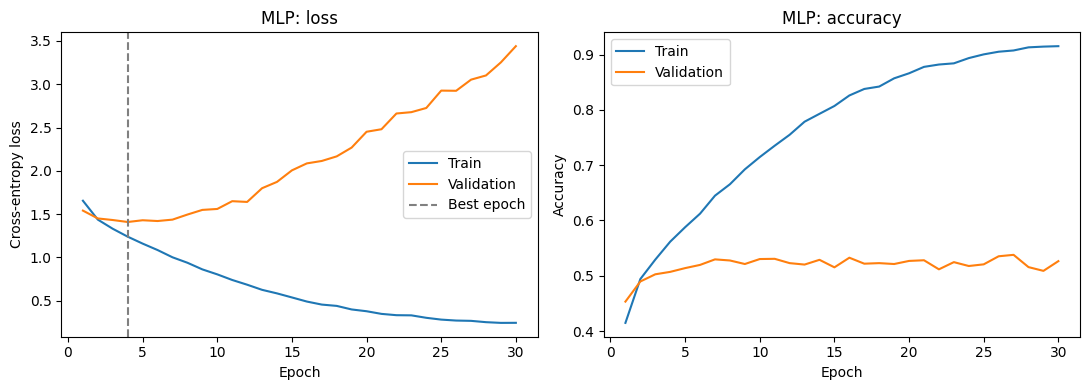

In [8]:
def plot_curves(hist, title, fname):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist["train_loss"], label="Train"); ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].axvline(hist["best_epoch"] + 1, ls="--", c="grey", label="Best epoch")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].set_title(f"{title}: loss"); ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="Train"); ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title(f"{title}: accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"figures/{fname}.png", dpi=200); plt.show()

plot_curves(hist_mlp, "MLP", "mlp_curves")

In [9]:
tr_l, tr_a = evaluate(mlp, train_loader_eval)       # clean training set, eval mode
va_l, va_a = evaluate(mlp, val_loader)
te_l, te_a = evaluate(mlp, test_loader)
print(f"Params {count_params(mlp):,}")
print(f"Train acc {tr_a:.4f} | Val acc {va_a:.4f} | Test acc {te_a:.4f} | Train-Test gap {tr_a - te_a:.4f}")

Params 1,707,274
Train acc 0.5980 | Val acc 0.5070 | Test acc 0.5095 | Train-Test gap 0.0885
